# 01 - Exploratory Data Analysis: UCI Heart Disease (Cleveland)

**Goal:** understand the data before modelling: missing values, distributions, class balance and which features relate to the target.

All figures are saved to `reports/figures/` for reuse in the final report.

In [12]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import (
    CATEGORICAL_FEATURES, NUMERIC_FEATURES, TARGET,
    clean, download_raw, load_raw,
)

FIG_DIR = ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {'No disease': '#4C72B0', 'Disease': '#DD8452'}
TARGET_LABELS = {0: 'No disease', 1: 'Disease'}

CAT_LABELS = {
    'sex': {0: 'Female', 1: 'Male'},
    'cp': {1: 'Typical angina', 2: 'Atypical angina', 3: 'Non-anginal', 4: 'Asymptomatic'},
    'fbs': {0: '<=120 mg/dl', 1: '>120 mg/dl'},
    'restecg': {0: 'Normal', 1: 'ST-T abnormality', 2: 'LV hypertrophy'},
    'exang': {0: 'No', 1: 'Yes'},
    'slope': {1: 'Upsloping', 2: 'Flat', 3: 'Downsloping'},
    'thal': {3: 'Normal', 6: 'Fixed defect', 7: 'Reversible defect'},
}

def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 1. Raw data and missing values

In [13]:
raw = load_raw(download_raw())
print('Raw shape:', raw.shape)
raw.head()

Raw shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [14]:
missing = raw.isna().sum()
missing[missing > 0]

ca      4
thal    2
dtype: int64

**Missing-value decision:** _(write your reasoning: how many rows are affected, why you chose to drop or impute, and what the pipeline will do at inference time)_

In [15]:
df = clean(raw, missing_strategy='drop')
df['diagnosis'] = df[TARGET].map(TARGET_LABELS)
print('Clean shape:', df.shape)
df[NUMERIC_FEATURES].describe().T.round(2)

Clean shape: (297, 15)


,count,mean,std,min,25%,50%,75%,max
age,297.0,54.54,9.05,29.0,48.0,56.0,61.0,77.0
trestbps,297.0,131.69,17.76,94.0,120.0,130.0,140.0,200.0
chol,297.0,247.35,52.00,126.0,211.0,243.0,276.0,564.0
thalach,297.0,149.60,22.94,71.0,133.0,153.0,166.0,202.0
oldpeak,297.0,1.06,1.17,0.0,0.0,0.8,1.6,6.2


## 2. Class balance

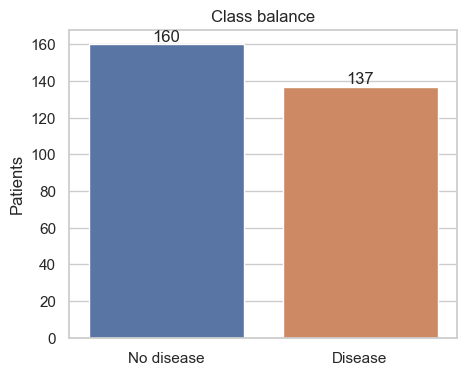

diagnosis
No disease    0.539
Disease       0.461
Name: proportion, dtype: float64

In [16]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x='diagnosis', hue='diagnosis', palette=PALETTE,
              order=['No disease', 'Disease'], legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%d')
ax.set(title='Class balance', xlabel='', ylabel='Patients')
save(fig, '01_class_balance')
plt.show()

df['diagnosis'].value_counts(normalize=True).round(3)

## 3. Numeric feature distributions

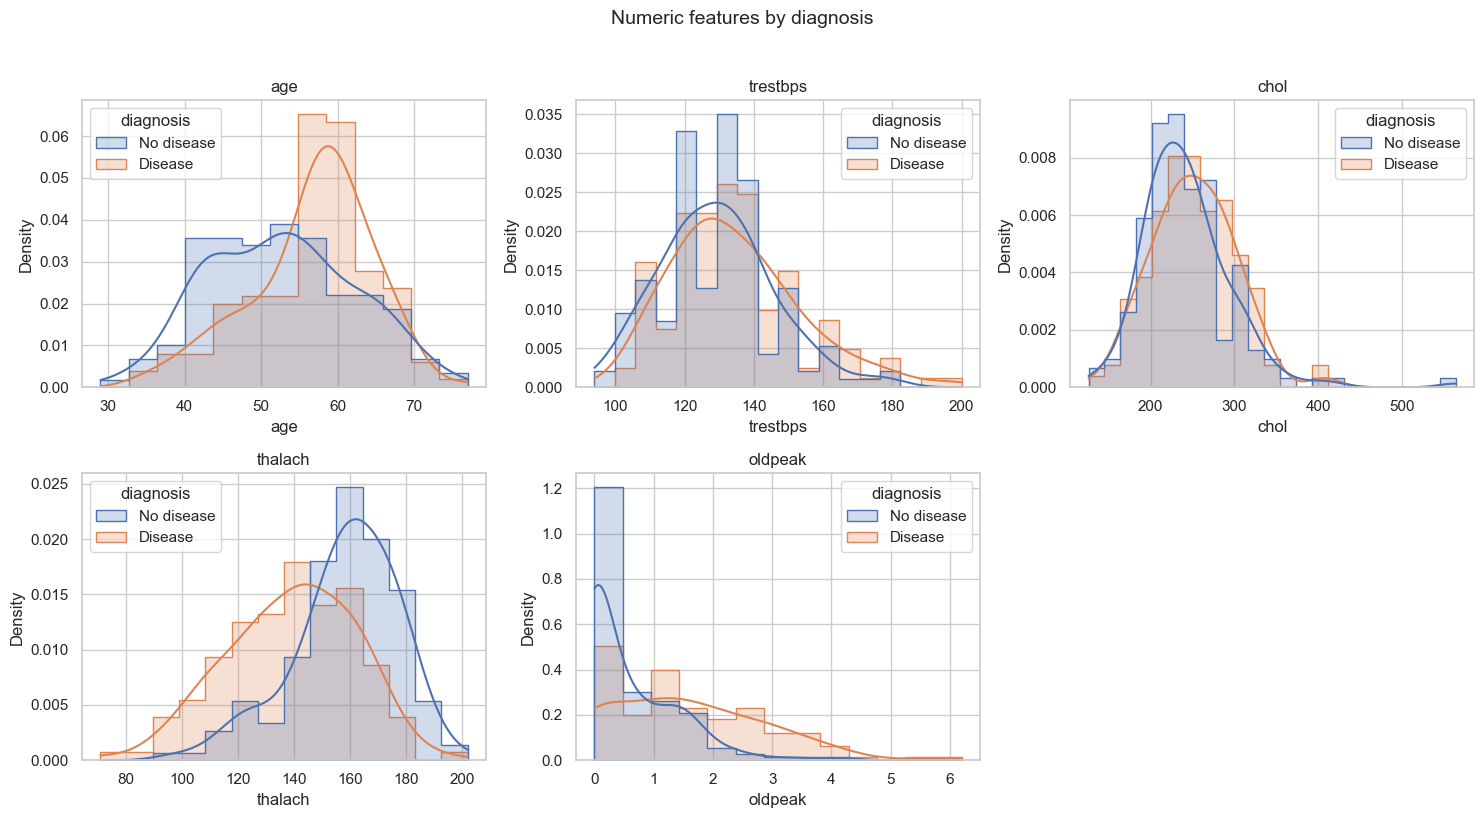

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.histplot(data=df, x=col, hue='diagnosis', palette=PALETTE, kde=True,
                 element='step', stat='density', common_norm=False, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis('off')
fig.suptitle('Numeric features by diagnosis', y=1.02, fontsize=14)
fig.tight_layout()
save(fig, '02_numeric_histograms')
plt.show()

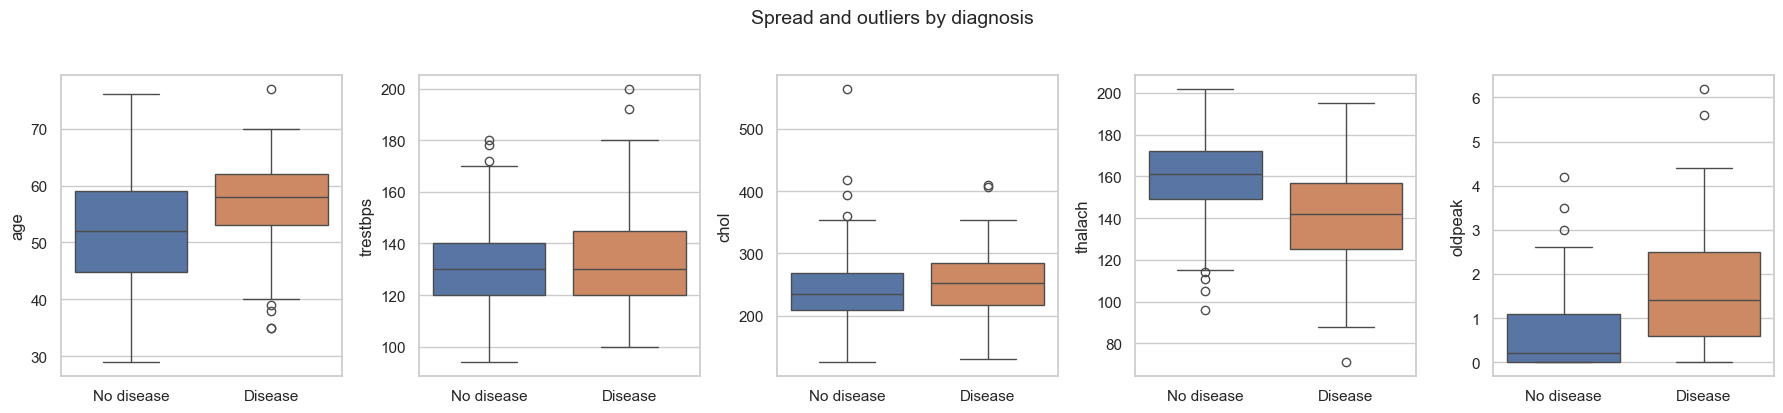

In [18]:
fig, axes = plt.subplots(1, len(NUMERIC_FEATURES), figsize=(18, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=df, x='diagnosis', y=col, hue='diagnosis', palette=PALETTE,
                order=['No disease', 'Disease'], legend=False, ax=ax)
    ax.set_xlabel('')
fig.suptitle('Spread and outliers by diagnosis', y=1.03, fontsize=14)
fig.tight_layout()
save(fig, '03_numeric_boxplots')
plt.show()

## 4. Categorical features

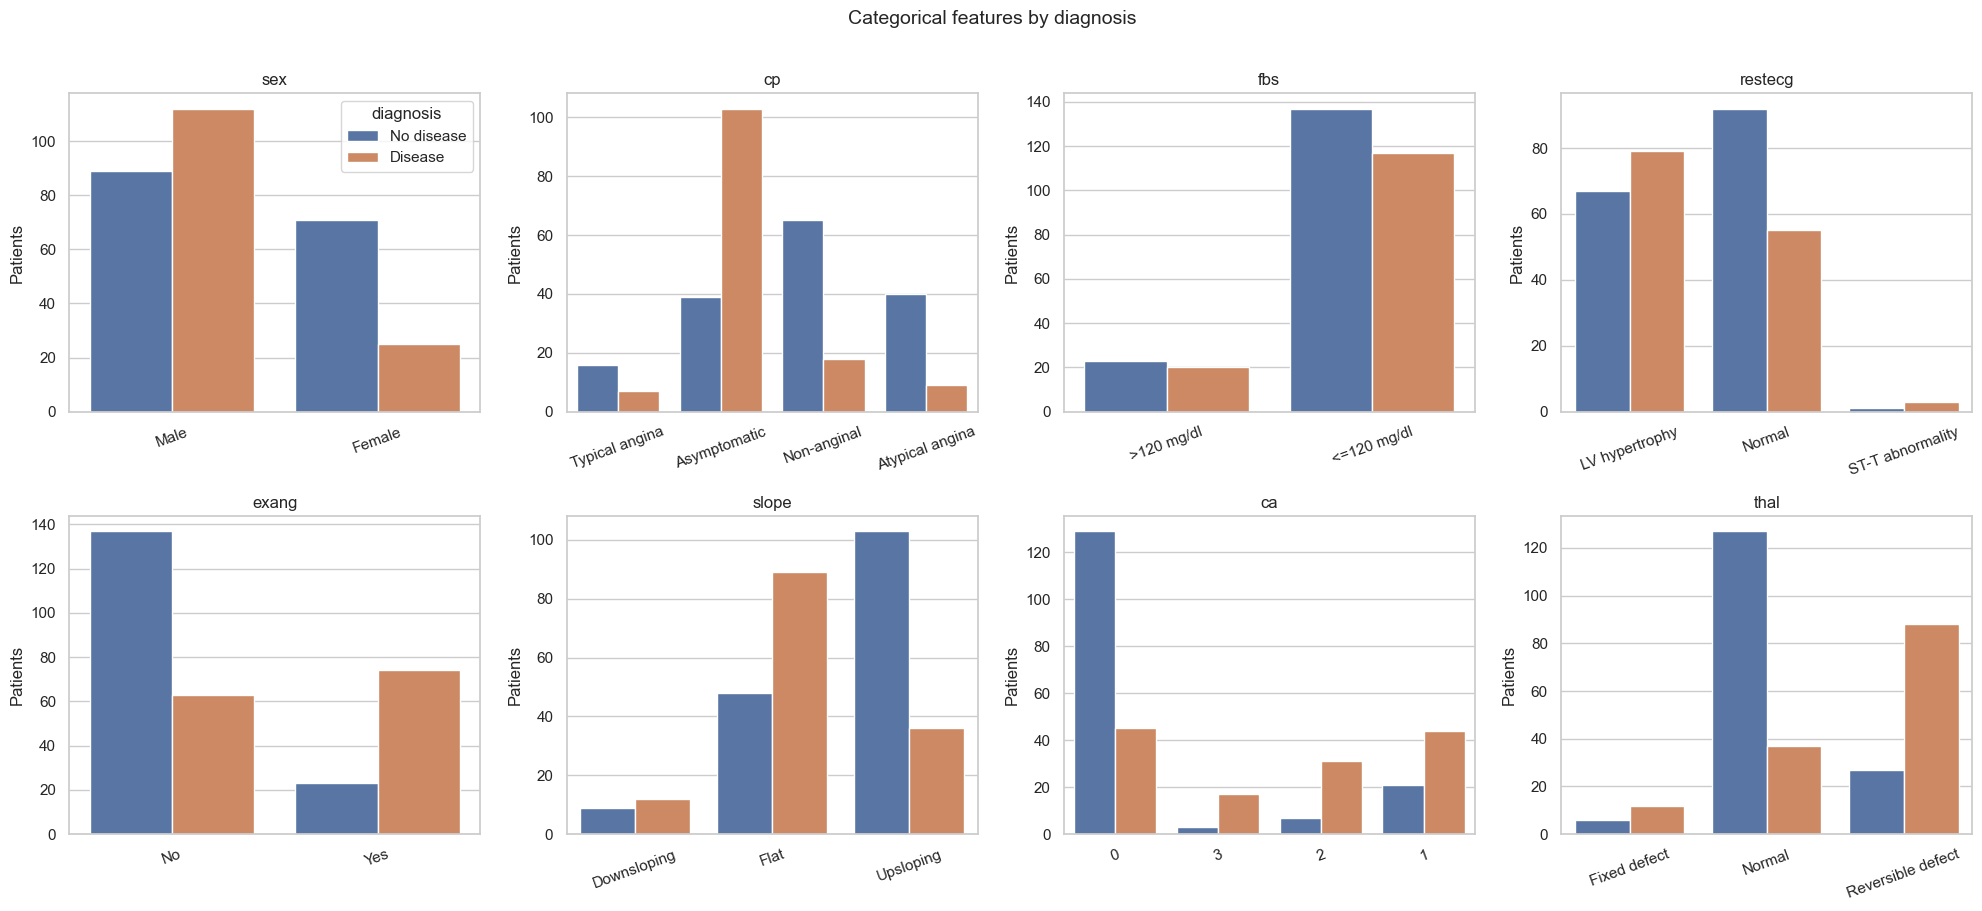

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for i, (ax, col) in enumerate(zip(axes.flat, CATEGORICAL_FEATURES)):
    labels = CAT_LABELS.get(col)
    x = df[col].map(labels) if labels else df[col].astype(str)
    sns.countplot(x=x, hue=df['diagnosis'], palette=PALETTE, ax=ax)
    ax.set(title=col, xlabel='', ylabel='Patients')
    ax.tick_params(axis='x', rotation=20)
    if i > 0 and ax.get_legend() is not None:
        ax.get_legend().remove()
fig.suptitle('Categorical features by diagnosis', y=1.01, fontsize=14)
fig.tight_layout()
save(fig, '04_categorical_counts')
plt.show()

In [20]:
# Share of patients with disease in each category
rates = {col: df.groupby(col)[TARGET].agg(['mean', 'size']) for col in CATEGORICAL_FEATURES}
rate_table = pd.concat(rates, names=['feature', 'value'])
rate_table.columns = ['disease_rate', 'n']
rate_table.round(2)

disease_rate    n
feature value                   
sex     0              0.26   96
        1              0.56  201
cp      1              0.30   23
        2              0.18   49
        3              0.22   83
        4              0.73  142
fbs     0              0.46  254
        1              0.47   43
restecg 0              0.37  147
        1              0.75    4
        2              0.54  146
exang   0              0.32  200
        1              0.76   97
slope   1              0.26  139
        2              0.65  137
        3              0.57   21
ca      0              0.26  174
        1              0.68   65
        2              0.82   38
        3              0.85   20
thal    3              0.23  164
        6              0.67   18
        7              0.77  115

## 5. Correlations

Pearson correlation on integer-coded categoricals is only approximate, but it is a quick way to spot strong relationships.

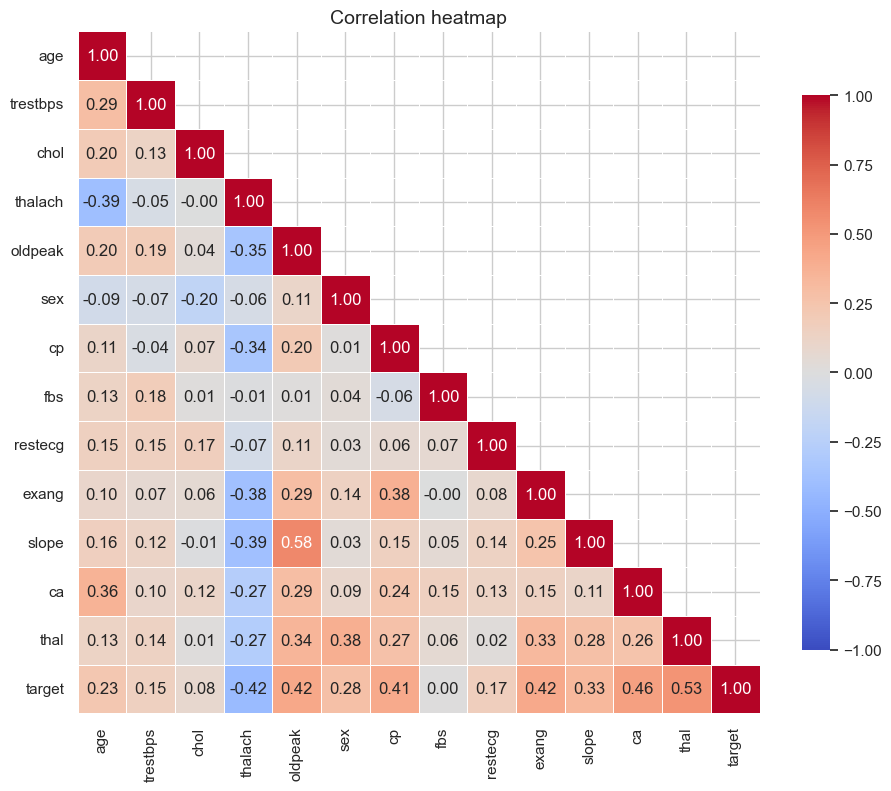

In [21]:
corr = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlation heatmap', fontsize=14)
save(fig, '05_correlation_heatmap')
plt.show()

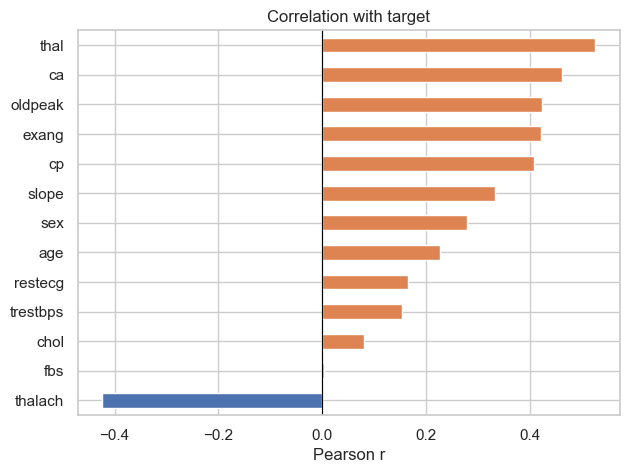

In [22]:
target_corr = corr[TARGET].drop(TARGET).sort_values()
colors = [PALETTE['Disease'] if v > 0 else PALETTE['No disease'] for v in target_corr]

fig, ax = plt.subplots(figsize=(7, 5))
target_corr.plot.barh(color=colors, ax=ax)
ax.axvline(0, color='black', lw=0.8)
ax.set(title='Correlation with target', xlabel='Pearson r')
save(fig, '06_target_correlation')
plt.show()

## 6. Summary of findings

_Write these in your own words after looking at the plots:_

- **Class balance:** is it balanced enough to use accuracy, or should you weight classes / focus on recall?
- **Strongest signals:** which 3-4 features separate the classes most clearly?
- **Surprises:** anything counter-intuitive (e.g. a feature you expected to matter that does not)?
- **Outliers:** any extreme values, and will you keep them?
- **Implications for modelling:** which features need scaling, which need one-hot encoding?